# Phase 2 – Notebook 1: History Features and ML Baselines

**What this notebook does (in simple words):**
1. Loads the flight data and builds new "history" features (how late were flights recently?).
2. Checks that these features do not leak future information.
3. Splits the data by time (train, validation, test).
4. Trains the Logistic Regression baseline twice: once with the old Phase 1 features, once with the new Phase 2 features.
5. Compares the results.

**Rule for prediction time:** we predict 2 hours before the scheduled departure. We only use information known before that time.

In [1]:
import sys, os
from pathlib import Path

# Work from the project root so imports and paths always work
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("Project root:", ROOT)

Project root: /Users/atharvatiwari/Desktop/flight-delay-prediction


## 1. Load data and create the target
A flight is **delayed (1)** if it arrives 15 or more minutes late. Flights with no arrival delay (cancelled) are removed.

In [2]:
from src.data_loader import load_data
from src.preprocessing import clean_data, create_target
from src.feature_engineering import FEATURE_COLUMNS
from src.phase2_history_features import (
    add_history_features, HISTORY_FEATURES, PHASE2_FEATURE_COLUMNS
)

raw_df = load_data()
clean_df = create_target(clean_data(raw_df))

print("Rows in raw data:", len(raw_df))
print("Rows with a known arrival delay:", len(clean_df))
print("Delay rate:", round(clean_df["delayed"].mean() * 100, 2), "%")

Rows in raw data: 336776
Rows with a known arrival delay: 327346
Delay rate: 24.47 %


## 2. Build the history features
There are 7 new features. All of them use only the past:
- `origin_delay_rate_last_3h`, `origin_avg_dep_delay_last_3h`, `origin_delay_rate_last_24h`: how late the flights from this airport were that had already left before the prediction time.
- `origin_flights_scheduled_same_hour`: how busy the airport is at that hour (the timetable is known in advance).
- `carrier_hist_delay_rate`, `route_hist_delay_rate`, `carrier_origin_hour_delay_rate`: how often this airline / route was late on **earlier days**.

If a value is missing (for example on the first day), we fill it with the average from the **training data only**.

In [3]:
df_p2, impute_stats = add_history_features(clean_df, train_ratio=0.70)

print("Shape after adding features:", df_p2.shape)
print("Missing values left in history features:", int(df_p2[HISTORY_FEATURES].isna().sum().sum()))
df_p2[["scheduled_datetime", "origin", "carrier"] + HISTORY_FEATURES].head()

Shape after adding features: (327346, 38)
Missing values left in history features: 0


,scheduled_datetime,origin,carrier,origin_delay_rate_last_3h,origin_avg_dep_delay_last_3h,origin_delay_rate_last_24h,origin_flights_scheduled_same_hour,carrier_hist_delay_rate,route_hist_delay_rate,carrier_origin_hour_delay_rate
0,2013-01-01 05:15:00,EWR,UA,0.167223,9.459838,0.23557,2.0,0.2461,0.245694,0.244733
1,2013-01-01 05:29:00,LGA,UA,0.167223,9.459838,0.23557,1.0,0.2461,0.245694,0.244733
2,2013-01-01 05:40:00,JFK,AA,0.167223,9.459838,0.23557,3.0,0.2461,0.245694,0.244733
3,2013-01-01 05:45:00,JFK,B6,0.167223,9.459838,0.23557,3.0,0.2461,0.245694,0.244733
4,2013-01-01 05:58:00,EWR,UA,0.167223,9.459838,0.23557,2.0,0.2461,0.245694,0.244733


In [4]:
summary = df_p2[HISTORY_FEATURES].describe().T[["mean", "std", "min", "max"]].round(3)
summary

,mean,std,min,max
origin_delay_rate_last_3h,0.157,0.164,0.0,1.000
origin_avg_dep_delay_last_3h,8.171,26.408,-15.0,508.000
origin_delay_rate_last_24h,0.220,0.125,0.0,0.791
origin_flights_scheduled_same_hour,20.048,5.902,1.0,38.000
carrier_hist_delay_rate,0.246,0.066,0.0,1.000
route_hist_delay_rate,0.245,0.074,0.0,1.000
carrier_origin_hour_delay_rate,0.244,0.115,0.0,1.000


## 3. Leakage check
We prove that the features do not use the future. The tests change the future data on purpose. If the feature of an earlier flight stays exactly the same, there is no leakage.

In [5]:
from tests.test_phase2_no_leakage import (
    test_forbidden_columns_excluded,
    test_rolling_origin_no_leakage,
    test_daily_history_no_leakage,
)

test_forbidden_columns_excluded()
test_rolling_origin_no_leakage()
test_daily_history_no_leakage()
print("All leakage tests passed.")

✓ Passed: All forbidden post-departure columns are excluded.
✓ Passed: Modifying future departures at or after T does not affect rolling features.
✓ Passed: Modifying same-day or future flight outcomes does not affect daily history.
All leakage tests passed.


## 4. Split the data by time
We never shuffle. The oldest 70% is training, the next 15% is validation, and the newest 15% is test. This is the same split as Phase 1.

**Important:** the validation period has a much lower delay rate than train and test. This is a known limitation and we mention it in the report.

In [6]:
n = len(df_p2)
train_end, val_end = int(n * 0.70), int(n * 0.85)

train_df = df_p2.iloc[:train_end].copy()
val_df   = df_p2.iloc[train_end:val_end].copy()
test_df  = df_p2.iloc[val_end:].copy()

y_train, y_val, y_test = train_df["delayed"], val_df["delayed"], test_df["delayed"]

split_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Flights": [len(train_df), len(val_df), len(test_df)],
    "From": [d["scheduled_datetime"].min().date() for d in (train_df, val_df, test_df)],
    "To":   [d["scheduled_datetime"].max().date() for d in (train_df, val_df, test_df)],
    "Delay rate %": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
})
split_table

,Split,Flights,From,To,Delay rate %
0,Train,229142,2013-01-01,2013-09-13,25.94
1,Validation,49102,2013-09-13,2013-11-06,15.39
2,Test,49102,2013-11-06,2013-12-31,26.69


## 5. Train the baselines
We train 2 models:
- Logistic Regression with **Phase 1 features** (16 features, schedule only)
- Logistic Regression with **Phase 2 features** (23 features, schedule + history)

For each model we pick the decision threshold **on the validation set only**, so that precision is about 0.40. Then we apply that same threshold on the test set.

In [7]:
from src.phase2_train import (
    train_logistic_regression,
    find_threshold_for_precision, evaluate_with_threshold,
)

setups = [
    ("Logistic Regression", "Phase 1 (16 features)", train_logistic_regression, FEATURE_COLUMNS, False),
    ("Logistic Regression", "Phase 2 (23 features)", train_logistic_regression, PHASE2_FEATURE_COLUMNS, True),
]

rows, trained = [], {}
for name, feats, trainer, cols, use_p2 in setups:
    print("Training:", name, "-", feats)
    model = trainer(train_df[cols], y_train, use_phase2=use_p2)
    val_probs  = model.predict_proba(val_df[cols])[:, 1]
    test_probs = model.predict_proba(test_df[cols])[:, 1]
    threshold  = find_threshold_for_precision(y_val, val_probs, target_precision=0.40)
    metrics    = evaluate_with_threshold(y_test, test_probs, threshold)
    rows.append({"Model": name, "Features": feats, **metrics})
    trained[(name, feats)] = model

results = pd.DataFrame(rows)
results[["Model", "Features", "threshold", "pr_auc", "roc_auc",
         "precision", "recall", "f1", "brier_score"]].round(4)

Training: Logistic Regression - Phase 1 (16 features)
Training: Logistic Regression - Phase 2 (23 features)


,Model,Features,threshold,pr_auc,roc_auc,precision,recall,f1,brier_score
0,Logistic Regression,Phase 1 (16 features),0.7103,0.3084,0.5682,0.0000,0.0000,0.0000,0.2092
1,Logistic Regression,Phase 2 (23 features),0.4842,0.4695,0.6676,0.6453,0.1825,0.2845,0.1785


In [8]:
metrics_dir = ROOT / "reports" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(metrics_dir / "phase2_baseline_comparison.csv", index=False)
print("Saved:", metrics_dir / "phase2_baseline_comparison.csv")

Saved: /Users/atharvatiwari/Desktop/flight-delay-prediction/reports/metrics/phase2_baseline_comparison.csv


## 6. Compare Phase 1 and Phase 2 features
PR AUC and ROC AUC do not depend on the threshold, so they are the fairest way to compare.

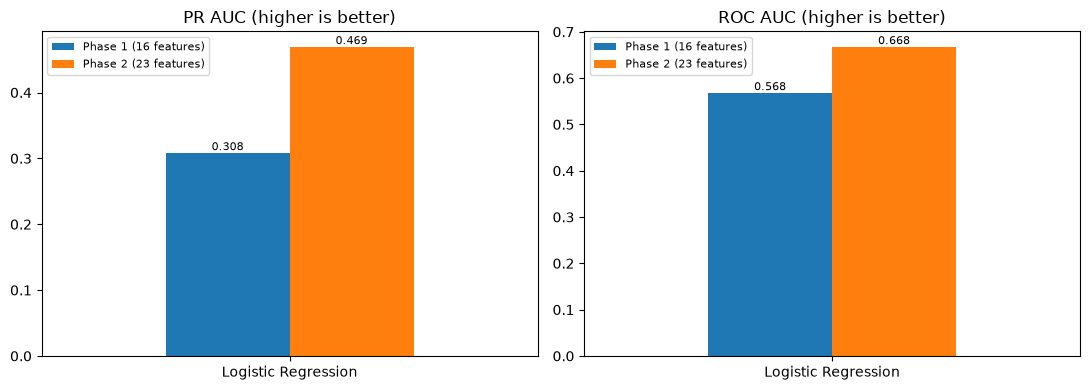

In [9]:
fig_dir = ROOT / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["pr_auc", "roc_auc"], ["PR AUC (higher is better)", "ROC AUC (higher is better)"]):
    pivot = results.pivot(index="Model", columns="Features", values=metric)
    pivot.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.legend(fontsize=8)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig(fig_dir / "phase2_baseline_comparison.png", dpi=150)
plt.show()

## 7. Which features matter most? (Logistic Regression, Phase 2)

In [10]:
lr_p2 = trained[("Logistic Regression", "Phase 2 (23 features)")]
feature_names = lr_p2.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(lr_p2.named_steps["classifier"].coef_[0], index=feature_names)
# Positive = pushes the delay risk up, negative = pushes it down.
# Numeric features are standardized, so their sizes can be compared with each other.
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(4)

categorical__dest_BDL                -0.7312
categorical__dest_PSE                -0.7266
numeric__origin_delay_rate_last_3h    0.6932
categorical__dest_DSM                -0.6214
categorical__dest_STT                 0.5666
categorical__carrier_AS              -0.4906
categorical__dest_SNA                -0.4890
categorical__dest_ALB                -0.4716
categorical__dest_ABQ                -0.4652
numeric__hour                         0.4207
dtype: float64

## What we learned
- The new history features improve Logistic Regression compared with Phase 1 features.
- (We will write the exact numbers here after the results are checked.)
- The validation delay rate (about 15%) is very different from train and test (about 26%). This makes threshold selection harder.